In [11]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Project folders
RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")

# Load cleaned datasets
matches = pd.read_csv(PROCESSED_DIR / "matches_cleaned.csv")
deliveries = pd.read_csv(PROCESSED_DIR / "deliveries_cleaned.csv")
points_table = pd.read_csv(PROCESSED_DIR / "points_table_cleaned.csv")

print("All datasets loaded successfully!")


All datasets loaded successfully!


In [12]:
print("Matches:", matches.shape)
print("Deliveries:", deliveries.shape)
print("Points Table:", points_table.shape)

Matches: (48, 17)
Deliveries: (26118, 20)
Points Table: (10, 11)


In [13]:
# Display all column names
print(deliveries.columns.tolist())

['match_id', 'season', 'start_date', 'venue', 'innings', 'ball', 'batting_team', 'bowling_team', 'striker', 'non_striker', 'bowler', 'runs_off_bat', 'extras', 'wides', 'noballs', 'byes', 'legbyes', 'penalty', 'wicket_type', 'player_dismissed']


,Batter,Total_Runs
0,V Kohli,765
1,RG Sharma,597
2,Q de Kock,594
3,R Ravindra,578
4,DJ Mitchell,552
5,DA Warner,535
6,SS Iyer,530
7,KL Rahul,452
8,HE van der Dussen,448
9,MR Marsh,441


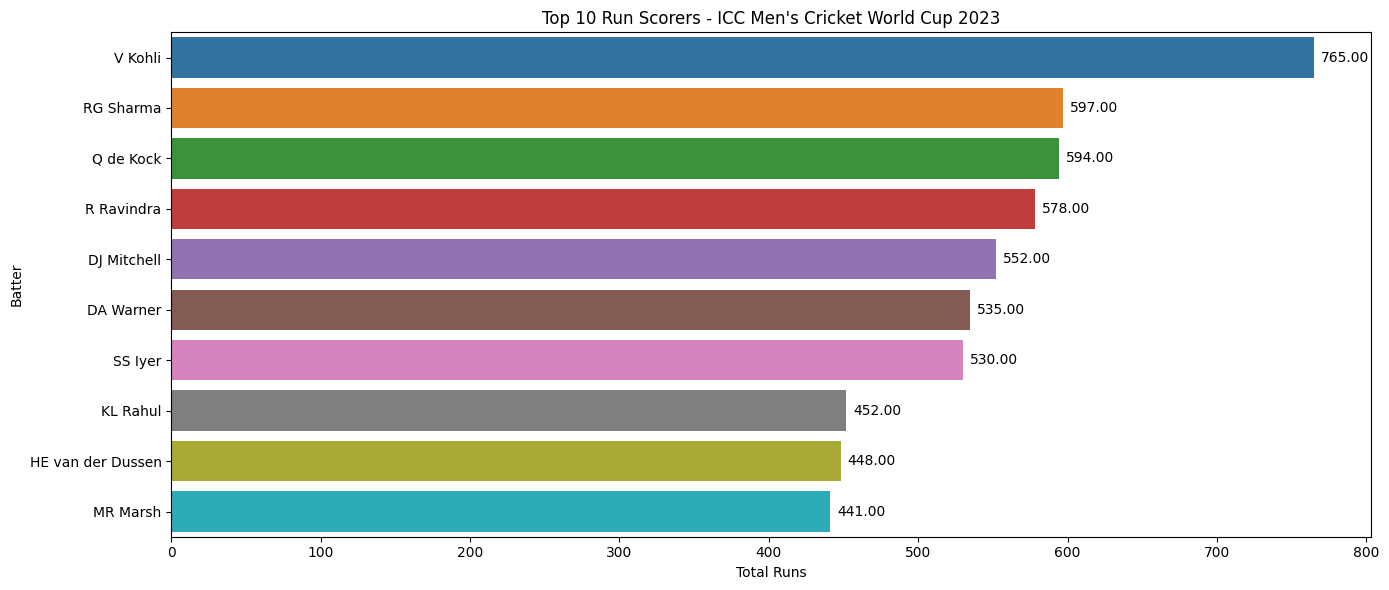

In [14]:
# Q1. Who were the top 10 run-scorers in the tournament?

batter_runs = (
    deliveries.groupby("striker")["runs_off_bat"]
    .sum()
    .reset_index()
)

# Rename column
batter_runs.columns = ["Batter", "Total_Runs"]

#sort by total_runs
batter_runs = batter_runs.sort_values(
    by="Total_Runs",
    ascending=False
).reset_index(drop=True)

display(batter_runs.head(10))

#select top 10 run scores
top_10_batters = batter_runs.head(10).sort_values(
    by="Total_Runs",
    ascending=False
)

plt.figure(figsize=(14,6))

ax = sns.barplot(
    data=top_10_batters,
    x="Total_Runs",
    y="Batter",
    hue="Batter"
)

# Add data labels
for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f"{bar.get_width():.2f}" for bar in container],
        padding=5,
        fontsize=10
    )
    
plt.title("Top 10 Run Scorers - ICC Men's Cricket World Cup 2023")
plt.xlabel("Total Runs")
plt.ylabel("Batter")

plt.tight_layout()
plt.show()

,Match_ID,Innings,Batter,Total_Runs
0,39,2,GJ Maxwell,201
1,43,2,MR Marsh,177
2,23,1,Q de Kock,174
3,18,1,DA Warner,163
4,1,2,DP Conway,152
5,7,1,DJ Malan,140
6,48,2,TM Head,137
7,46,2,DJ Mitchell,134
8,32,1,HE van der Dussen,133
9,8,2,Mohammad Rizwan,131


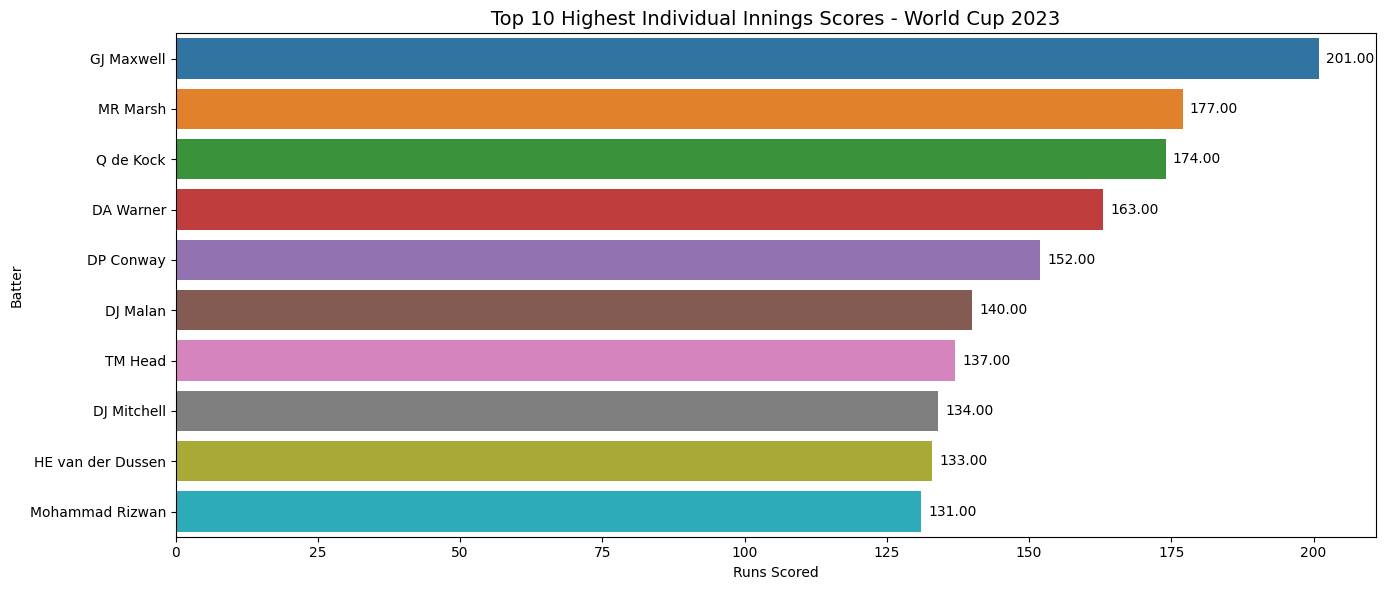

In [15]:
# Q2. Which batters recorded the highest individual innings scores?
individual_scores = (
    deliveries.groupby(["match_id", "innings", "striker"])["runs_off_bat"]
    .sum()
    .reset_index()
)

individual_scores.columns = [
    "Match_ID", "Innings", "Batter", "Total_Runs"
]

# sort by highest individual score
individual_scores = individual_scores.sort_values(
    by="Total_Runs",
    ascending=False
).reset_index(drop=True)

display(individual_scores.head(10))

top_10_scores = individual_scores.head(10).sort_values(
    by="Total_Runs",
    ascending=False
)

plt.figure(figsize=(14, 6))

ax = sns.barplot(
    data=top_10_scores,
    x="Total_Runs",
    y="Batter",
    hue="Batter"
)


# Add data labels
for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f"{bar.get_width():.2f}" for bar in container],
        padding=5,
        fontsize=10
    )

plt.title("Top 10 Highest Individual Innings Scores - World Cup 2023",
          fontsize=14)
plt.xlabel("Runs Scored")
plt.ylabel("Batter")

plt.tight_layout()
plt.show()


,Batter,Centuries,Half_Centuries
0,Q de Kock,4,0
1,V Kohli,3,6
2,R Ravindra,3,2
3,SS Iyer,2,3
4,DA Warner,2,2
5,DJ Mitchell,2,2
6,HE van der Dussen,2,2
7,MR Marsh,2,1
8,TM Head,2,1
9,GJ Maxwell,2,0


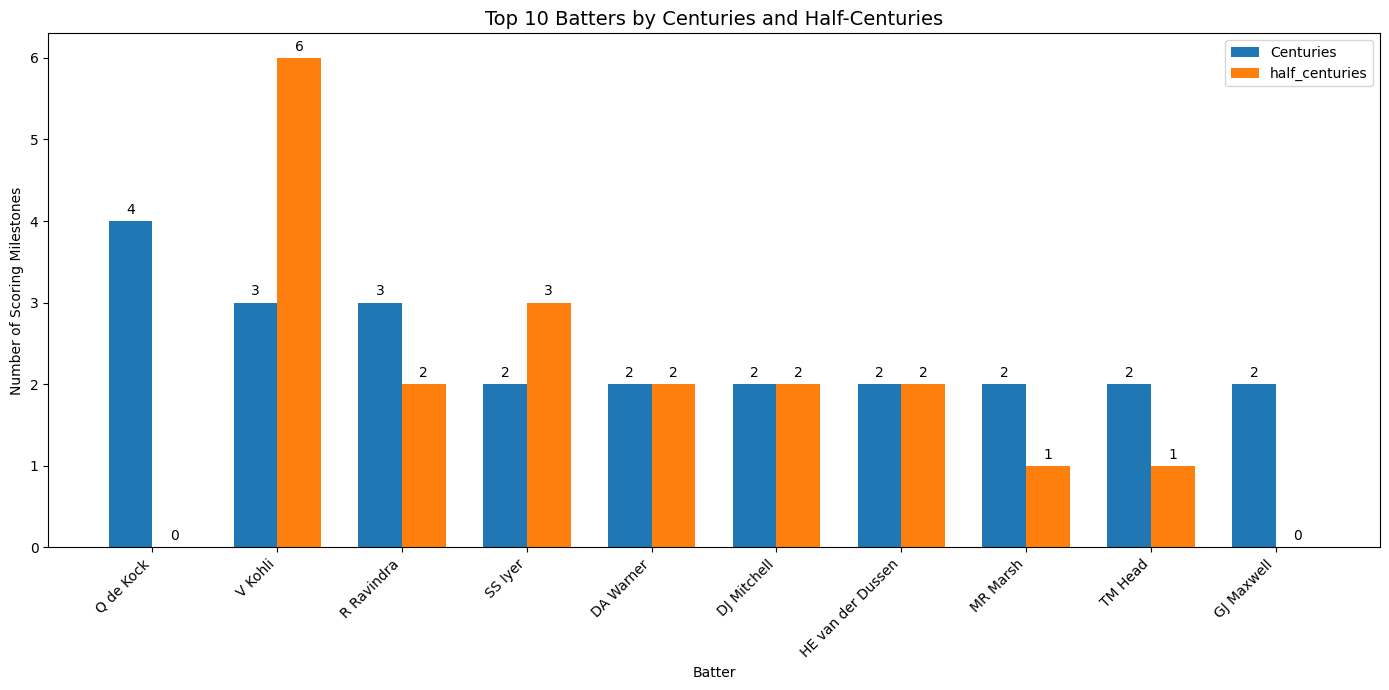

In [16]:
# Q3. Which batters scored the most centuries and half-centuries?
individual_scores = (
    deliveries.groupby(["match_id", "innings", "striker"])["runs_off_bat"]
    .sum()
    .reset_index()
)

individual_scores.columns = ["Match_ID", "Innings", "Batter", "Runs"]

# count century and half-century for each batter
centuries = (
    individual_scores[individual_scores["Runs"] >= 100]
    .groupby("Batter")
    .size()
    .rename("Centuries")
)

half_centuries = (
    individual_scores[
        (individual_scores["Runs"] >= 50) &
        (individual_scores["Runs"] < 100)
    ]
    .groupby("Batter")
    .size()
    .rename("Half_Centuries")
)

# combine results
batting_milestones = (
    centuries.to_frame()
    .join(half_centuries, how="outer")
    .fillna(0)
    .astype(int)
    .reset_index()
)

# Sort by centuries, then half-centuries
batting_milestones = batting_milestones.sort_values(
    by=["Centuries", "Half_Centuries"],
    ascending=False
).reset_index(drop=True)

display(batting_milestones.head(10))

# select top 10 batters
top_10 = batting_milestones.head(10).copy()

# Positions andbar width
x = np.arange(len(top_10))
width = 0.35

# Create grouped bar chart
fix, ax = plt.subplots(figsize=(14,7))

bars1 = ax.bar(
    x - width / 2,
    top_10["Centuries"],
    width,
    label="Centuries"
)

bars2 = ax.bar(
    x + width / 2,
    top_10["Half_Centuries"],
    width,
    label="half_centuries"
)

# Add data labels
ax.bar_label(bars1, padding=3)
ax.bar_label(bars2, padding=3)

# Titles and labels
ax.set_title(
    "Top 10 Batters by Centuries and Half-Centuries",
    fontsize=14
)

ax.set_xlabel("Batter")
ax.set_ylabel("Number of Scoring Milestones")
ax.set_xticks(x)
ax.set_xticklabels(top_10["Batter"], rotation=45, ha="right")
ax.legend()

plt.tight_layout()
plt.show()

,Batter,Fours,Sixes,Total_Boundaries
0,RG Sharma,66,31,97
1,Q de Kock,57,21,78
2,V Kohli,68,9,77
3,DA Warner,50,24,74
4,R Ravindra,55,17,72
5,DJ Mitchell,48,22,70
6,MR Marsh,43,21,64
7,GJ Maxwell,40,22,62
8,SS Iyer,37,24,61
9,DJ Malan,50,9,59


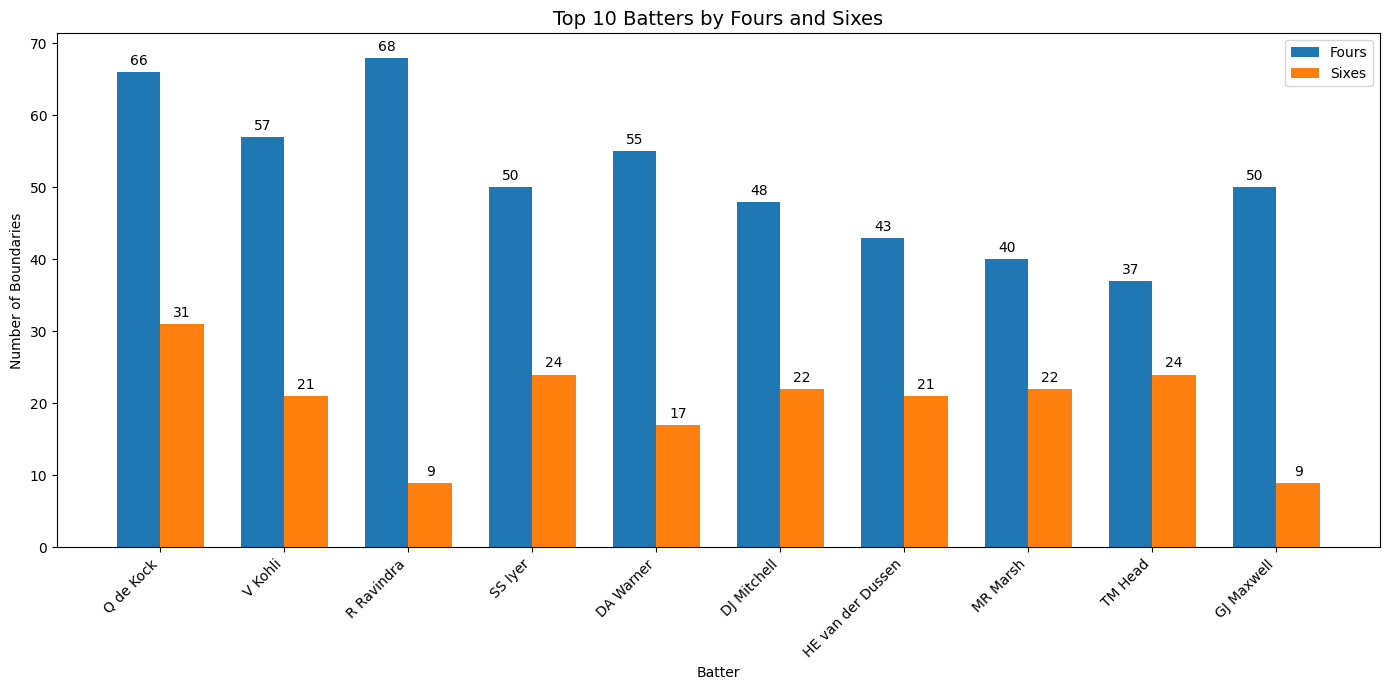

In [17]:
# Q4. Which batters hit the highest number of fours and sixes?

boundary_stats = deliveries.groupby("striker").agg(
    Fours=("runs_off_bat", lambda x: (x == 4).sum()),
    Sixes=("runs_off_bat", lambda x: (x == 6).sum())
).reset_index()

boundary_stats.columns = ["Batter", "Fours", "Sixes"]

# sort by total boundaries
boundary_stats["Total_Boundaries"] = (
    boundary_stats["Fours"] + boundary_stats["Sixes"]
)

boundary_stats = boundary_stats.sort_values(
    by="Total_Boundaries",
    ascending=False
).reset_index(drop=True)

display(boundary_stats.head(10))

top_10_batters = boundary_stats.head(10).copy()

# set bar positions and width
x = np.arange(len(top_10_batters))
width = 0.35

# create grouped bar chart
fig, ax = plt.subplots(figsize=(14,7))

bars1 = ax.bar(
    x - width / 2,
    top_10_batters["Fours"],
    width,
    label = "Fours"
)

bars2 = ax.bar(
    x + width / 2,
    top_10_batters["Sixes"],
    width,
    label="Sixes"
)

# Display values on bars
ax.bar_label(bars1, padding=3)
ax.bar_label(bars2, padding=3)


# Add title and labels
ax.set_title("Top 10 Batters by Fours and Sixes", fontsize=14)
ax.set_xlabel("Batter")
ax.set_ylabel("Number of Boundaries")
ax.set_xticks(x)
ax.set_xticklabels(top_10["Batter"], rotation=45, ha="right")
ax.legend()

plt.tight_layout()
plt.show()

,striker,Total_Runs,Balls_Faced,Strike_Rate
0,GJ Maxwell,400,266,150.38
1,H Klaasen,373,280,133.21
2,MA Wood,85,65,130.77
3,TM Head,329,258,127.52
4,MJ Santner,103,81,127.16
5,RG Sharma,597,474,125.95
6,Fakhar Zaman,220,179,122.91
7,MS Chapman,84,71,118.31
8,DJ Willey,78,67,116.42
9,Iftikhar Ahmed,142,123,115.45


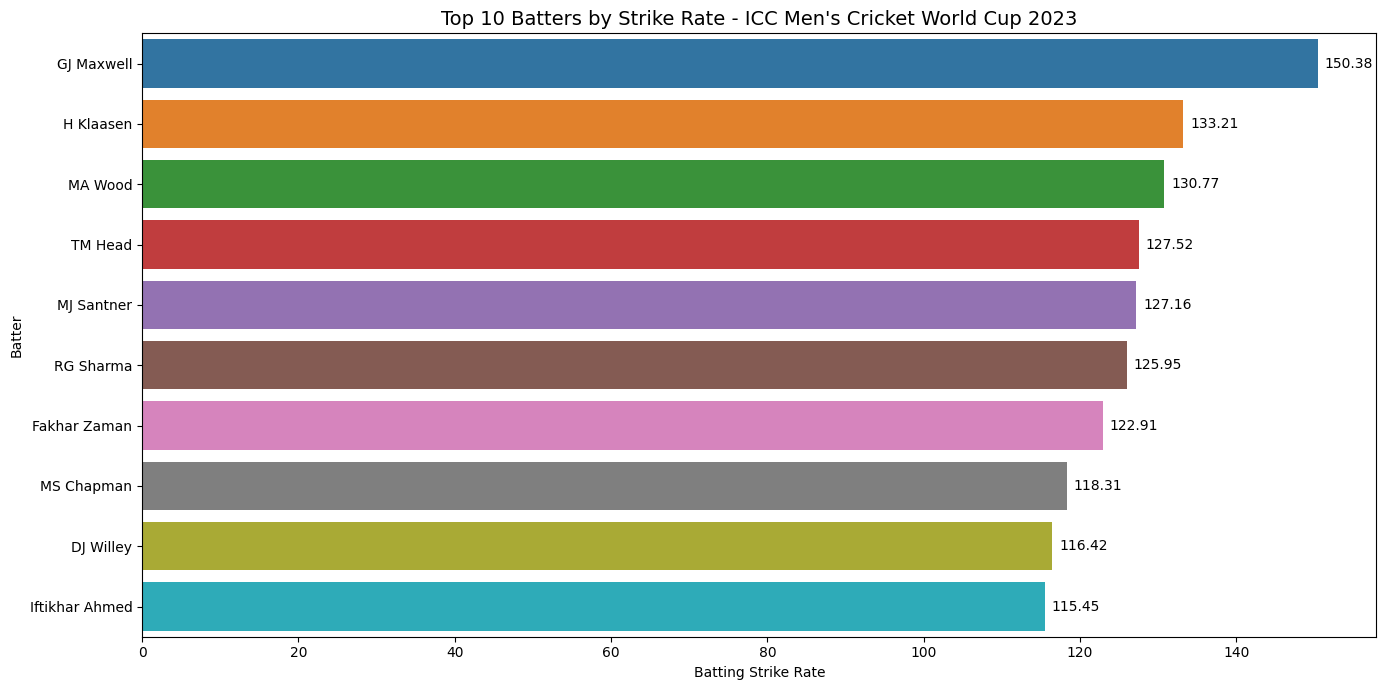

In [18]:
# Q5. Which batters achieved the highest batting strike rates, subject to a minimum balls-faced threshold?


strike_rate_stats = deliveries.groupby("striker").agg(
    Total_Runs=("runs_off_bat", "sum"),
    Balls_Faced=("wides", lambda x: 0)
).reset_index()

# Balls faced exclude wides
balls_faced = deliveries.assign(
    valid_ball = (deliveries["wides"].isna() | deliveries["wides"] == 0)
).groupby("striker")["valid_ball"].sum().reset_index(name="Balls_Faced")


# Merge runs and balls faced
strike_rate_stats = (
    strike_rate_stats[["striker", "Total_Runs"]]
    .merge(balls_faced, on="striker")
    
)

# Apply minimum balls-faced threshold
MIN_BALLS = 60

strike_rate_stats = strike_rate_stats[
    strike_rate_stats["Balls_Faced"] >= MIN_BALLS
].copy()

# calculate batting strike rate 
strike_rate_stats["Strike_Rate"] = (
    strike_rate_stats["Total_Runs"] / strike_rate_stats["Balls_Faced"] * 100
).round(2)

# sort by strike rate 

strike_rate_stats = strike_rate_stats.sort_values(
    by="Strike_Rate",
    ascending=False
).reset_index(drop=True)

display(strike_rate_stats.head(10))


# top_10_strikers
top_10_striker_rates = strike_rate_stats.head(10).sort_values(
    by="Strike_Rate",
    ascending=False
)


plt.figure(figsize=(14,7))

ax = sns.barplot(
    data=top_10_striker_rates,
    x="Strike_Rate",
    y="striker",
    hue="striker"
)

# Add data labels
for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f"{bar.get_width():.2f}" for bar in container],
        padding=5,
        fontsize=10
    )
plt.title("Top 10 Batters by Strike Rate - ICC Men's Cricket World Cup 2023",
          fontsize=14)
plt.xlabel("Batting Strike Rate")
plt.ylabel("Batter")

plt.tight_layout()
plt.show()

,Team,Total_Runs
0,India,3038
1,Australia,2945
2,South Africa,2773
3,New Zealand,2712
4,Pakistan,2220
5,England,2135
6,Afghanistan,1990
7,Bangladesh,1944
8,Sri Lanka,1942
9,Netherlands,1728


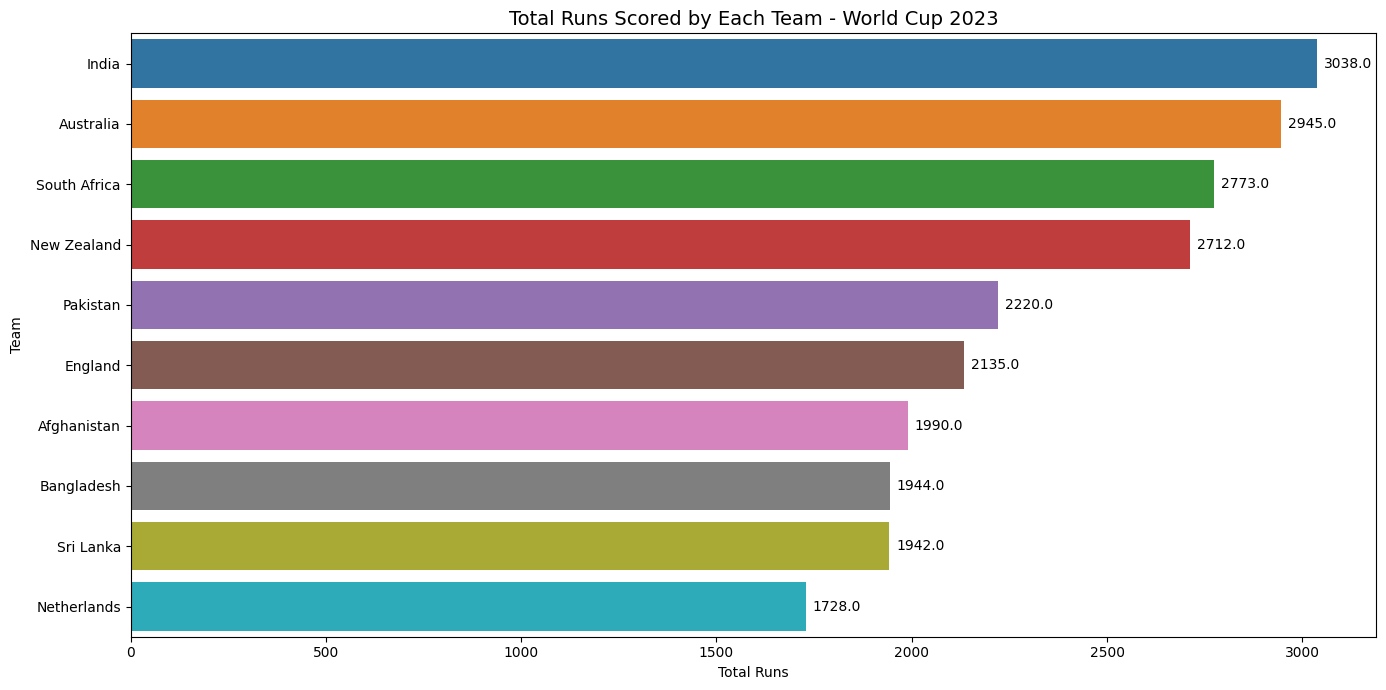

In [19]:
# Q6. Which teams accumulated the highest total number of runs?

team_runs = (
    deliveries.groupby("batting_team")["runs_off_bat"].sum().reset_index()
    
)

team_runs.columns = ["Team", "Total_Runs"]

# sort by total runs
team_runs = team_runs.sort_values(
    by="Total_Runs",
    ascending=False
).reset_index(drop=True)

display(team_runs)

plt.figure(figsize=(14, 7))

ax = sns.barplot(
    data=team_runs,
    x="Total_Runs",
    y="Team",
    hue="Team"
)

# Add data labels
for container in ax.containers:
    ax.bar_label(
        container, 
        labels=[f"{bar.get_width():.1f}" for bar in container],
        padding=5,
        fontsize=10
        
    )
    
plt.title("Total Runs Scored by Each Team - World Cup 2023", fontsize=14)
plt.xlabel("Total Runs")
plt.ylabel("Team")

plt.tight_layout()
plt.show()

,Match_Phase,Total_Runs
0,Powerplay,5035
1,Middle Overs,14224
2,Death Overs,3753


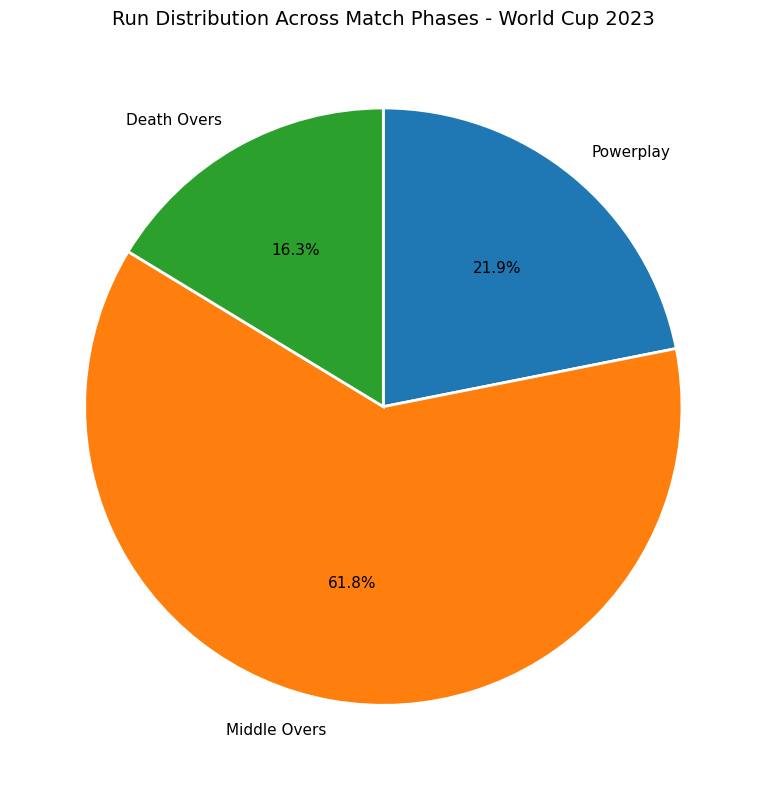

In [20]:
# Q7. How were runs distributed across the Powerplay, middle overs, and death overs?

# Define match phases based on over number
deliveries["over_number"] = deliveries["ball"].astype(str).str.split(".").str[0].astype(int)

deliveries["Match_Phase"] = deliveries["over_number"].apply(
    lambda over: (
        "Powerplay" if 1 <= over <= 10
        else "Middle Overs" if 11 <= over <= 40
        else "Death Overs" if 41 <= over <= 50
        else "Unknown"
    )
)

# Calculate total runs by match phase
phase_runs = (
    deliveries.groupby("Match_Phase")["runs_off_bat"]
    .sum()
    .reindex(["Powerplay", "Middle Overs", "Death Overs"])
    .reset_index()
)

phase_runs.columns = ["Match_Phase", "Total_Runs"]

display(phase_runs)

# data 
labels = phase_runs["Match_Phase"]
runs = phase_runs["Total_Runs"]

plt.figure(figsize=(8,8))

plt.pie(
    runs,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    wedgeprops={"edgecolor":"white", "linewidth":2},
    textprops={"fontsize":11}
)

plt.title("Run Distribution Across Match Phases - World Cup 2023",
          fontsize=14)

plt.tight_layout()
plt.show()